#  Business Analysis
This notebook answers sales, customer, product, cohort, delivery, and review questions using the prepared tables.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path("..").resolve()
DATA_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

orders = pd.read_csv(DATA_DIR / "orders.csv", parse_dates=[
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
])
customers = pd.read_csv(DATA_DIR / "customers.csv")
items = pd.read_csv(DATA_DIR / "items.csv")
payments = pd.read_csv(DATA_DIR / "payments.csv")
reviews = pd.read_csv(DATA_DIR / "reviews.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
sellers = pd.read_csv(DATA_DIR / "sellers.csv")
category_translation = pd.read_csv(DATA_DIR / "category_translation.csv")

print("Tables loaded. Orders:", len(orders), "| Items:", len(items))

Tables loaded. Orders: 99441 | Items: 112650


## 1. Build an order-customer table

In [3]:
order_customers = orders.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator=True
)
print("Orders rows:", len(orders))
print("Merged rows:", len(order_customers))
display(order_customers["_merge"].value_counts().to_frame("rows"))
order_customers = order_customers.drop(columns="_merge")

Orders rows: 99441
Merged rows: 99441


,rows
_merge,
both,99441
left_only,0
right_only,0


## Create safe order-level item and payment totals

In [4]:
item_order = (
    items.groupby("order_id", as_index=False)
    .agg(item_revenue=("price", "sum"),
         freight_value=("freight_value", "sum"),
         item_count=("order_item_id", "count"))
)
payment_order = (
    payments.groupby("order_id", as_index=False)
    .agg(payment_total=("payment_value", "sum"),
         payment_records=("payment_sequential", "count"))
)

order_fact = (
    order_customers
    .merge(item_order, on="order_id", how="left", validate="one_to_one")
    .merge(payment_order, on="order_id", how="left", validate="one_to_one")
)

print("Order-level rows:", len(order_fact))
display(order_fact[["order_id", "order_status", "item_revenue", "freight_value", "payment_total"]].head())

Order-level rows: 99441


,order_id,order_status,item_revenue,freight_value,payment_total
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,29.99,8.72,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,118.70,22.76,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,159.90,19.22,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,45.00,27.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,19.90,8.72,28.62


##  Executive KPIs

In [5]:
delivered = order_fact[order_fact["order_status"].eq("delivered")].copy()
total_orders = order_fact["order_id"].nunique()
delivered_orders = delivered["order_id"].nunique()
unique_customers = order_fact["customer_unique_id"].nunique()
delivered_item_revenue = delivered["item_revenue"].sum()
delivered_aov = delivered_item_revenue / delivered_orders if delivered_orders else np.nan
cancelled_orders = order_fact.loc[order_fact["order_status"].eq("canceled"), "order_id"].nunique()
cancel_rate = cancelled_orders / total_orders * 100 if total_orders else np.nan

kpis = pd.DataFrame([
    ("All orders", total_orders),
    ("Delivered orders", delivered_orders),
    ("Unique customer identities", unique_customers),
    ("Delivered item revenue (excludes freight)", round(delivered_item_revenue, 2)),
    ("Average delivered order item value", round(delivered_aov, 2)),
    ("Cancelled orders", cancelled_orders),
    ("Cancellation rate (%)", round(cancel_rate, 2)),
], columns=["KPI", "Value"])
display(kpis)
kpis.to_csv(OUTPUT_DIR / "executive_kpis.csv", index=False)

,KPI,Value
0,All orders,99441.00
1,Delivered orders,96478.00
2,Unique customer identities,96096.00
3,Delivered item revenue (excludes freight),13221498.11
4,Average delivered order item value,137.04
5,Cancelled orders,625.00
6,Cancellation rate (%),0.63


## Monthly order and item-revenue trend


,purchase_month,orders,item_revenue
0,2016-09,1,134.97
1,2016-10,265,40325.11
2,2016-12,1,10.90
3,2017-01,750,111798.36
4,2017-02,1653,234223.40


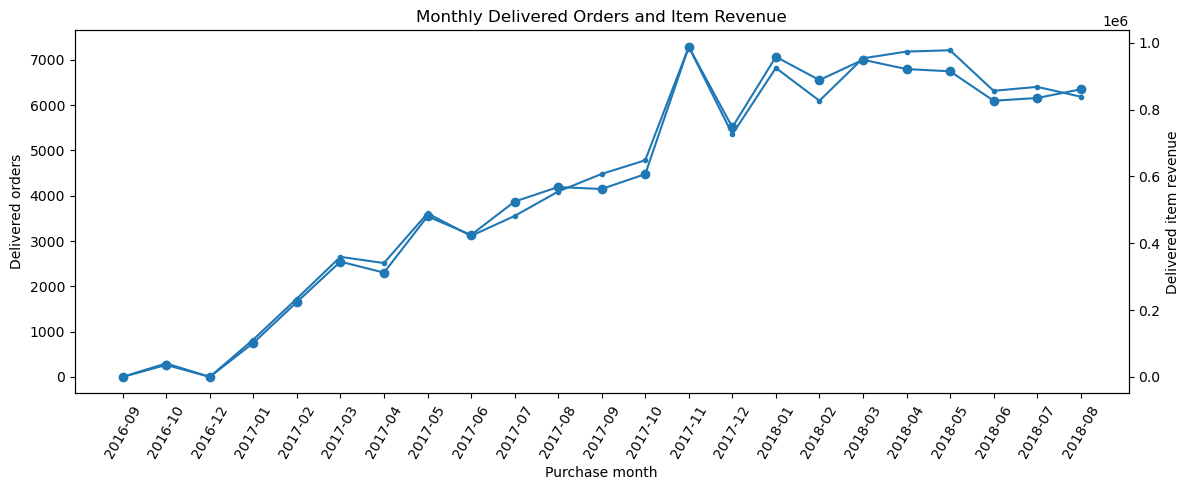

In [6]:
delivered["purchase_month"] = delivered["order_purchase_timestamp"].dt.to_period("M").astype("string")
monthly = (
    delivered.dropna(subset=["purchase_month"])
    .groupby("purchase_month", as_index=False)
    .agg(orders=("order_id", "nunique"), item_revenue=("item_revenue", "sum"))
    .sort_values("purchase_month")
)
display(monthly.head())
monthly.to_csv(OUTPUT_DIR / "monthly_sales_trend.csv", index=False)

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(monthly["purchase_month"], monthly["orders"], marker="o")
ax1.set_xlabel("Purchase month")
ax1.set_ylabel("Delivered orders")
ax1.set_title("Monthly Delivered Orders and Item Revenue")
ax1.tick_params(axis="x", rotation=60)
ax2 = ax1.twinx()
ax2.plot(monthly["purchase_month"], monthly["item_revenue"], marker=".")
ax2.set_ylabel("Delivered item revenue")
fig.tight_layout()
plt.show()

##  Product category performance


,category,item_revenue,orders,items_sold
43,health_beauty,1233131.72,8647,9465
73,watches_gifts,1166176.98,5495,5859
7,bed_bath_table,1023434.76,9272,10953
67,sports_leisure,954852.55,7530,8431
15,computers_accessories,888724.61,6530,7644
39,furniture_decor,711927.69,6307,8160
49,housewares,615628.69,5743,6795
20,cool_stuff,610204.10,3559,3718
5,auto,578966.65,3810,4140
71,toys,471286.48,3804,4030


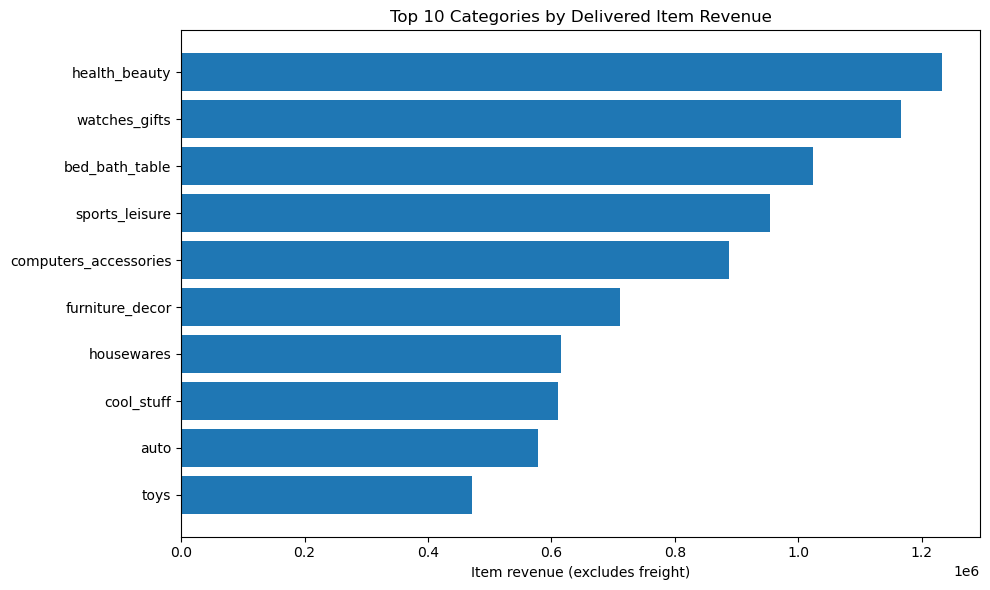

In [7]:
items_products = (
    items.merge(products, on="product_id", how="left", validate="many_to_one")
    .merge(category_translation, on="product_category_name", how="left", validate="many_to_one")
    .merge(orders[["order_id", "order_status"]], on="order_id", how="left", validate="many_to_one")
)
delivered_items = items_products[items_products["order_status"].eq("delivered")].copy()
delivered_items["category"] = (
    delivered_items["product_category_name_english"]
    .fillna(delivered_items["product_category_name"])
    .fillna("unknown")
)
category_perf = (
    delivered_items.groupby("category", as_index=False)
    .agg(item_revenue=("price", "sum"),
         orders=("order_id", "nunique"),
         items_sold=("order_item_id", "count"))
    .sort_values("item_revenue", ascending=False)
)
display(category_perf.head(15))
category_perf.to_csv(OUTPUT_DIR / "category_performance.csv", index=False)

top_cat = category_perf.head(10).sort_values("item_revenue")
plt.figure(figsize=(10, 6))
plt.barh(top_cat["category"], top_cat["item_revenue"])
plt.title("Top 10 Categories by Delivered Item Revenue")
plt.xlabel("Item revenue (excludes freight)")
plt.tight_layout()
plt.show()

## Customer repeat-purchase analysis


In [8]:
customer_orders = (
    delivered[["customer_unique_id", "order_id", "order_purchase_timestamp"]]
    .dropna(subset=["customer_unique_id", "order_purchase_timestamp"])
)
customer_frequency = (
    customer_orders.groupby("customer_unique_id", as_index=False)
    .agg(order_count=("order_id", "nunique"),
         last_purchase=("order_purchase_timestamp", "max"))
)
customer_count = customer_frequency["customer_unique_id"].nunique()
repeat_customers = int((customer_frequency["order_count"] >= 2).sum())
repeat_rate = repeat_customers / customer_count * 100 if customer_count else np.nan

print(f"Customers with delivered orders: {customer_count:,}")
print(f"Customers with 2+ delivered orders: {repeat_customers:,}")
print(f"Repeat-customer rate: {repeat_rate:.2f}%")
display(customer_frequency["order_count"].value_counts().sort_index().head(10).to_frame("customers"))
customer_frequency.to_csv(OUTPUT_DIR / "customer_order_frequency.csv", index=False)

Customers with delivered orders: 93,358
Customers with 2+ delivered orders: 2,801
Repeat-customer rate: 3.00%


,customers
order_count,
1,90557
2,2573
3,181
4,28
5,9
6,5
7,3
9,1
15,1


## Monthly cohort retention

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.0,NaN,NaN,NaN,NaN,NaN,0.4,NaN,NaN,0.4,NaN,0.4,NaN,0.4,NaN,0.4,NaN,0.4,0.8,0.8
2016-12,100.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.0,0.3,0.3,0.1,0.4,0.1,0.4,0.1,0.1,NaN,0.4,0.1,0.7,0.4,0.1,0.1,0.3,0.4,0.1,NaN
2017-02,100.0,0.2,0.3,0.1,0.4,0.1,0.2,0.2,0.1,0.2,0.1,0.3,0.1,0.2,0.1,0.1,0.1,0.2,NaN,NaN
2017-03,100.0,0.4,0.4,0.4,0.4,0.2,0.2,0.3,0.3,0.1,0.4,0.1,0.2,0.1,0.2,0.2,0.1,0.1,NaN,NaN
2017-04,100.0,0.6,0.2,0.2,0.3,0.3,0.4,0.3,0.3,0.2,0.3,0.1,0.0,0.0,0.1,0.1,0.1,NaN,NaN,NaN
2017-05,100.0,0.5,0.5,0.3,0.3,0.3,0.4,0.1,0.3,0.3,0.3,0.3,0.2,0.0,0.2,0.2,NaN,NaN,NaN,NaN
2017-06,100.0,0.5,0.4,0.4,0.3,0.4,0.4,0.2,0.1,0.2,0.3,0.4,0.2,0.2,0.2,NaN,NaN,NaN,NaN,NaN


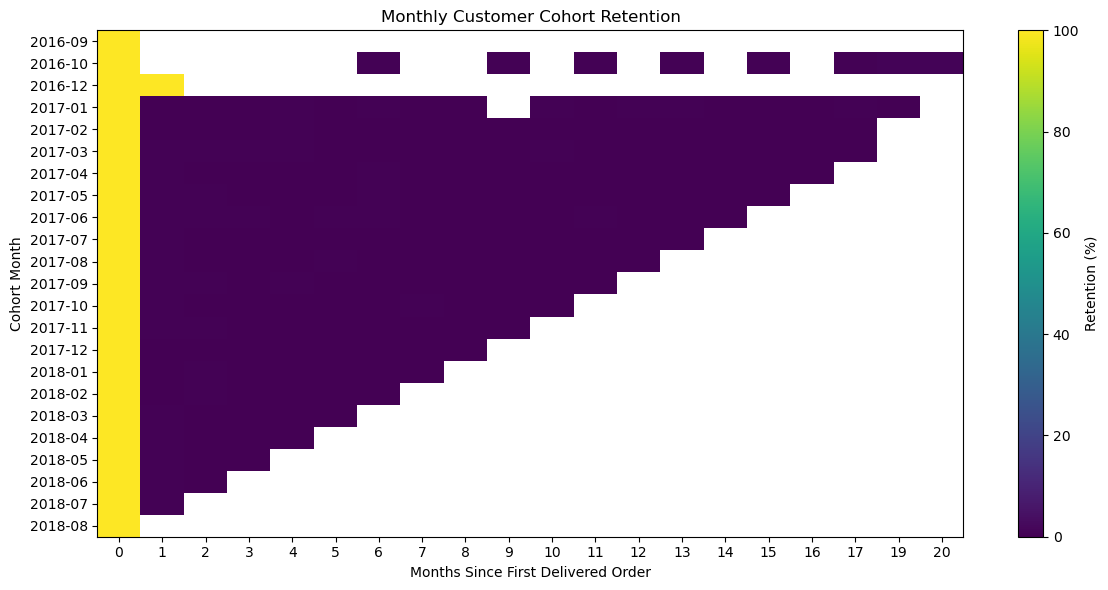

In [9]:
cohort_base = customer_orders.copy()
cohort_base["purchase_month"] = cohort_base["order_purchase_timestamp"].dt.to_period("M")
cohort_base["cohort_month"] = cohort_base.groupby("customer_unique_id")["purchase_month"].transform("min")
cohort_base["cohort_index"] = (
    (cohort_base["purchase_month"].dt.year - cohort_base["cohort_month"].dt.year) * 12
    + (cohort_base["purchase_month"].dt.month - cohort_base["cohort_month"].dt.month)
)
cohort_counts = (
    cohort_base.groupby(["cohort_month", "cohort_index"])["customer_unique_id"]
    .nunique().reset_index(name="active_customers")
)
cohort_sizes = (
    cohort_counts[cohort_counts["cohort_index"] == 0]
    [["cohort_month", "active_customers"]]
    .rename(columns={"active_customers": "cohort_size"})
)
cohort_counts = cohort_counts.merge(cohort_sizes, on="cohort_month", how="left")
cohort_counts["retention_pct"] = (cohort_counts["active_customers"] / cohort_counts["cohort_size"] * 100).round(1)
cohort_pivot = cohort_counts.pivot(index="cohort_month", columns="cohort_index", values="retention_pct")
display(cohort_pivot)
cohort_counts.to_csv(OUTPUT_DIR / "cohort_retention_long.csv", index=False)
cohort_pivot.to_csv(OUTPUT_DIR / "cohort_retention_matrix.csv")

plt.figure(figsize=(12, 6))
plt.imshow(cohort_pivot.fillna(np.nan), aspect="auto", interpolation="nearest")
plt.colorbar(label="Retention (%)")
plt.title("Monthly Customer Cohort Retention")
plt.xlabel("Months Since First Delivered Order")
plt.ylabel("Cohort Month")
plt.xticks(range(len(cohort_pivot.columns)), cohort_pivot.columns)
plt.yticks(range(len(cohort_pivot.index)), [str(x) for x in cohort_pivot.index])
plt.tight_layout()
plt.show()

## Simple RFM segmentation


In [10]:
order_item_values = (
    delivered[["order_id", "customer_unique_id", "order_purchase_timestamp", "item_revenue"]]
    .dropna(subset=["customer_unique_id", "order_purchase_timestamp"])
)
reference_date = order_item_values["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
rfm = (
    order_item_values.groupby("customer_unique_id", as_index=False)
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("item_revenue", "sum")
    )
)
rfm["recency_days"] = (reference_date - rfm["last_purchase"]).dt.days
rfm["r_score"] = pd.qcut(rfm["recency_days"].rank(method="first"), 4, labels=[4,3,2,1]).astype(int)
rfm["f_score"] = pd.qcut(rfm["frequency"].rank(method="first"), 4, labels=[1,2,3,4]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 4, labels=[1,2,3,4]).astype(int)

def segment_customer(row):
    if row["r_score"] >= 3 and row["f_score"] >= 3:
        return "Loyal / Active"
    if row["r_score"] <= 2 and row["f_score"] >= 3:
        return "At Risk - Previously Frequent"
    if row["r_score"] >= 3 and row["f_score"] <= 2:
        return "Recent / Promising"
    return "Needs Attention"

rfm["segment"] = rfm.apply(segment_customer, axis=1)
rfm_summary = (
    rfm.groupby("segment", as_index=False)
    .agg(customers=("customer_unique_id", "nunique"),
         average_monetary=("monetary", "mean"),
         total_item_revenue=("monetary", "sum"))
    .sort_values("customers", ascending=False)
)
display(rfm_summary)
rfm.to_csv(OUTPUT_DIR / "customer_rfm.csv", index=False)
rfm_summary.to_csv(OUTPUT_DIR / "rfm_segment_summary.csv", index=False)

,segment,customers,average_monetary,total_item_revenue
1,Loyal / Active,23355,147.237831,3438739.55
2,Needs Attention,23355,138.853458,3242922.51
0,At Risk - Previously Frequent,23324,142.904029,3333093.57
3,Recent / Promising,23324,137.486815,3206742.48


## Delivery and customer experience


In [11]:
delivery = order_fact.copy()
delivery["delivery_days"] = (
    delivery["order_delivered_customer_date"] - delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400
delivery["is_late"] = (
    delivery["order_delivered_customer_date"] > delivery["order_estimated_delivery_date"]
)
delivery_delivered = delivery[
    delivery["order_status"].eq("delivered")
    & delivery["order_delivered_customer_date"].notna()
    & delivery["order_estimated_delivery_date"].notna()
].copy()

delivery_summary = delivery_delivered.groupby("is_late", as_index=False).agg(
    orders=("order_id", "nunique"),
    avg_delivery_days=("delivery_days", "mean")
)
display(delivery_summary)

review_order = reviews.groupby("order_id", as_index=False).agg(
    review_score=("review_score", "mean"),
    review_records=("review_id", "nunique")
)
experience = delivery_delivered.merge(review_order, on="order_id", how="left", validate="one_to_one")
experience_summary = experience.groupby("is_late", as_index=False).agg(
    orders=("order_id", "nunique"),
    average_review_score=("review_score", "mean")
)
display(experience_summary)
delivery_summary.to_csv(OUTPUT_DIR / "delivery_summary.csv", index=False)
experience_summary.to_csv(OUTPUT_DIR / "delivery_review_summary.csv", index=False)

,is_late,orders,avg_delivery_days
0,False,88644,10.88426
1,True,7826,31.51889


,is_late,orders,average_review_score
0,False,88644,4.294292
1,True,7826,2.566506


In [13]:
order_fact.to_csv(OUTPUT_DIR / "order_fact.csv", index=False)
category_perf.to_csv(OUTPUT_DIR / "category_performance.csv", index=False)
monthly.to_csv(OUTPUT_DIR / "monthly_sales_trend.csv", index=False)
customer_frequency.to_csv(OUTPUT_DIR / "customer_order_frequency.csv", index=False)
cohort_pivot.to_csv(OUTPUT_DIR / "cohort_retention_matrix.csv")
rfm.to_csv(OUTPUT_DIR / "customer_rfm.csv", index=False)
print("Power BI-ready outputs saved in:", OUTPUT_DIR)

Power BI-ready outputs saved in: C:\Users\dharmveer patel\OneDrive\Desktop\ecommerce_customer_intelligence_major_project_complete\ecommerce_customer_intelligence_major_project\outputs
